# FreeCodeCamp Sci-Kit Tutorial Notes

Content: 
* Part 1: Scikit-Learn
* Part 2: Preprocessing
* Part 3: Metrics
* Part 4: Meta Estimators
* Part 5: Human-Learn

## Part 1: Scikit Learn

**Data Description for Dataset**
| Variable | Description |
|---|---|
| CRIM | Per capita crime rate by town |
| ZN | Proportion of residential land zoned for lots over 25,000 sq.ft. |
| INDUS | Proportion of non-retail business acres per town |
| CHAS | Charles River dummy variable (= 1 if tract bounds river; 0 otherwise) |
| NOX | Nitric oxides concentration (parts per 10 million) |
| RM | Average number of rooms per dwelling |
| AGE | Proportion of owner-occupied units built prior to 1940 |
| DIS | Weighted distances to five Boston employment centres |
| RAD | Index of accessibility to radial highways |
| TAX | Full-value property-tax rate per $10,000 |
| PTRATIO | Pupil-teacher ratio by town |
| B | 1000(Bk - 0.63)^2 where Bk is the proportion of blacks by town |
| LSTAT | % lower status of the population |
| MEDV | Median value of owner-occupied homes in $1000's |

In [2]:
# import modules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# using dummy dataset - boston housing dataset
data_url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
df = pd.read_csv(data_url)
df.columns = df.columns.str.upper() 

X = df.drop(columns="MEDV").values
y = df["MEDV"].values

## **Using scikit learn**

Machine learning with scikit-learn usually follows these steps: 

1. Data Preprocessing
2. Model Creation
3. Model fitting 
4. Prediction

Let's see an example using K-nearest neighbour regression (without the preprocessing step).

In [4]:
# import models to apply to dataset
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression


In [5]:
# 1. create model
mod = KNeighborsRegressor()

# 2. fit model to data
mod.fit(X, y)

# 3. predict
pred = mod.predict(X)

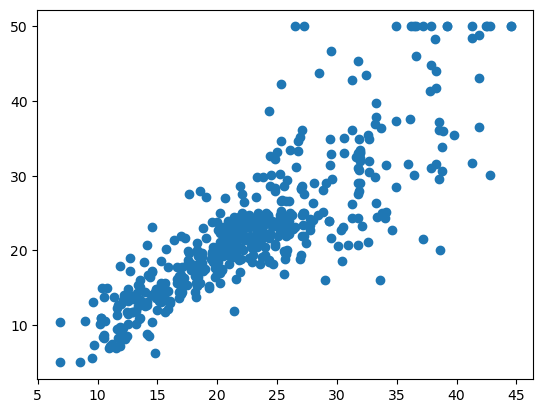

In [6]:
# plotting the accuracy of predictions
plt.scatter(pred, y)
plt.show()

Note our predicted results here are contained within the training set. The goal is to get a feel of how scikit-learn works.  

## **Machine Learning Pipeline in Scikit Learn**

A **pipeline** in scikit-learn chains several steps into one model (object).

* Eg. Scaling data (preprocessing) $\rightarrow$ train model. 

This is useful as the **whole chain forms a single model** (or object), which we can apply `.fit()` and `.predict()`. 

To create a pipeline we apply `Pipeline()` where paramters are entered as a **list of tuples** (name of step, estimator).

Additionally, we can call `.get_params()` on our pipeline object which returns a *dict* of parameters. 

In [7]:
# import preprocessing and pipeline modules
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

### Standard Scalar 

We use the `StandardScaler()` method to normalize the data for KNN. 

By default, `StandardScaler()` applied **z-score normalisation (aka standardisation)** which rescales each feature so it has a **mean of 0** and **standard deviation of 1**. 

This places every feature on the same scale. 

In [8]:
# create pipeline 
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsRegressor(n_neighbors=1))
])

# check params 
pipe.get_params()

{'memory': None,
 'steps': [('scale', StandardScaler()),
  ('model', KNeighborsRegressor(n_neighbors=1))],
 'transform_input': None,
 'verbose': False,
 'scale': StandardScaler(),
 'model': KNeighborsRegressor(n_neighbors=1),
 'scale__copy': True,
 'scale__with_mean': True,
 'scale__with_std': True,
 'model__algorithm': 'auto',
 'model__leaf_size': 30,
 'model__metric': 'minkowski',
 'model__metric_params': None,
 'model__n_jobs': None,
 'model__n_neighbors': 1,
 'model__p': 2,
 'model__weights': 'uniform'}

In [9]:
# fit pipeline 
pipe.fit(X, y)

,steps,"[('scale', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_neighbors,1
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30


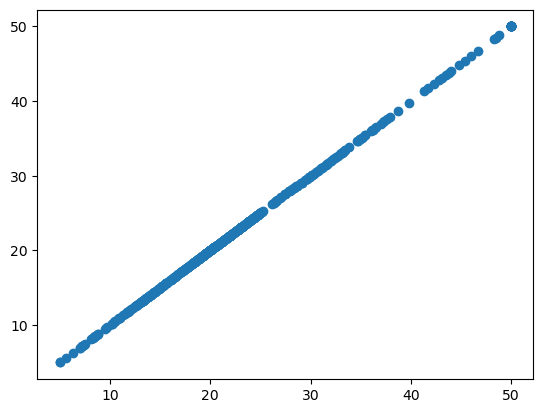

In [10]:
# predict
pred = pipe.predict(X)

# visualize
plt.scatter(pred, y)
plt.show()

### GridSearchCV

`GridsearchCV` tries every combination of hyperparameter values passed, scores each one via cross-validation, and returns the best. 

Params: 
* **estimator='pipeline':** The model to tune that gets re-fitted inside every fold. 
* **param_grid={'stepname__parameter':** ['values']}** The settings to try. 
* **cv=$k$:** Number of folds for cross validation. 

Benefits of GridSearchCV:
* **Estimating Real Performance:** More reliable score than one split
* **Choosing Hyperparamters:** Compare different values for a model by CV scores, allowing us to choose the best one.
* **Spotting Overfitting:** I

### Cross Validation

**Cross-validation** checks how well a model works on new data by testing it on several different train/test splits instead of just one. 

**How k-fold cross-validation works:**

With **5-fold** cross-validation: 

1. Training data is split into 5 equal parts (folds).
2. Train on 4 folds and test on 1.
3. Repeat 5 times, so each fold gets one turn as test set.
4. Return a cross-validation (CV) score = **average** of the $k = 5$ scores.  


Round 1:  [TEST] [train] [train] [train] [train] \
Round 2:  [train] [TEST] [train] [train] [train] \
Round 3:  [train] [train] [TEST] [train] [train] \
Round 4:  [train] [train] [train] [TEST] [train] \
Round 5:  [train] [train] [train] [train] [TEST] 

In [11]:
# import gridsearch
from sklearn.model_selection import GridSearchCV

In [12]:
# create GridSearchCV
mod = GridSearchCV(estimator=pipe,                                                # model to tune
             param_grid={'model__n_neighbors': [1,2,3,4,5,6,7,8,9,10]},     # hyperparameter values to evaluate
             cv=3)                                                          # number of cross-validation folds

In [13]:
# fit (train) the gridsearch
mod.fit(X, y)

,estimator,Pipeline(step...eighbors=1))])
,param_grid,"{'model__n_neighbors': [1, 2, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


We can look evaluate the results from the gridsearch using `cv_results_` and passing it into a **pandas dataframe.**

In [14]:
# evaluate results from GridSearchCV in pandas
pd.DataFrame(mod.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
0,0.000582,0.000222,0.000829,0.000343,1,{'model__n_neighbors': 1},0.226933,0.432998,0.127635,0.262522,0.127179,10
1,0.000285,0.000028,0.000462,0.000041,2,{'model__n_neighbors': 2},0.358216,0.409229,0.172294,0.313246,0.101821,9
2,0.000337,0.000052,0.000574,0.000056,3,{'model__n_neighbors': 3},0.413515,0.476651,0.318534,0.402900,0.064986,1
3,0.000397,0.000154,0.000566,0.000099,4,{'model__n_neighbors': 4},0.475349,0.402495,0.273014,0.383619,0.083675,7
4,0.000262,0.000007,0.000495,0.000036,5,{'model__n_neighbors': 5},0.512318,0.347951,0.262590,0.374286,0.103638,8
5,0.000251,0.000001,0.000493,0.000030,6,{'model__n_neighbors': 6},0.533611,0.389504,0.248482,0.390532,0.116406,6
6,0.000268,0.000017,0.000545,0.000046,7,{'model__n_neighbors': 7},0.544782,0.385199,0.243668,0.391216,0.123003,5
7,0.000413,0.000137,0.000652,0.000078,8,{'model__n_neighbors': 8},0.589644,0.394650,0.209714,0.398003,0.155124,2
8,0.000294,0.000035,0.000568,0.000056,9,{'model__n_neighbors': 9},0.590352,0.407556,0.185253,0.394387,0.165643,3
9,0.000266,0.000014,0.000577,0.000037,10,{'model__n_neighbors': 10},0.616510,0.395077,0.164023,0.391870,0.184741,4


## Part 2: Preprocessing

In [27]:
# import data
df = pd.read_csv('drawndata1.csv')
print(df.head())

# set X and y values
X = df[['x', 'y']].values
y = df['z'] == 'a'
X

            x           y  z
0   58.080365  225.699042  a
1  238.867357  247.456645  a
2  156.218212  286.588782  a
3  262.004361  284.251445  a
4  185.243183  308.187571  a


array([[ 5.80803655e+01,  2.25699042e+02],
       [ 2.38867357e+02,  2.47456645e+02],
       [ 1.56218212e+02,  2.86588782e+02],
       [ 2.62004361e+02,  2.84251445e+02],
       [ 1.85243183e+02,  3.08187571e+02],
       [ 1.80095699e+02,  2.89569088e+02],
       [ 2.54567182e+02,  2.88434128e+02],
       [ 2.83587488e+02,  3.05608829e+02],
       [ 1.33750000e+02,  3.11215526e+02],
       [ 4.29660811e+02,  2.65006662e+02],
       [ 3.32910896e+02,  2.61581219e+02],
       [ 3.36778928e+02,  2.56307498e+02],
       [ 1.61129229e+01,  1.91083191e+02],
       [ 2.31967953e+02,  2.08907046e+02],
       [ 2.75937636e+02,  2.20157136e+02],
       [ 4.01967688e+02,  1.82034090e+02],
       [ 3.34785168e+01,  1.75722269e+02],
       [ 1.42187622e+02,  1.88445365e+02],
       [ 2.37558919e+02,  1.77092071e+02],
       [ 1.55172776e+02,  1.78877970e+02],
       [ 4.01681078e+01,  2.17438131e+02],
       [ 1.22382254e+02,  2.21463367e+02],
       [ 4.06950923e+01,  2.36848927e+02],
       [ 1.

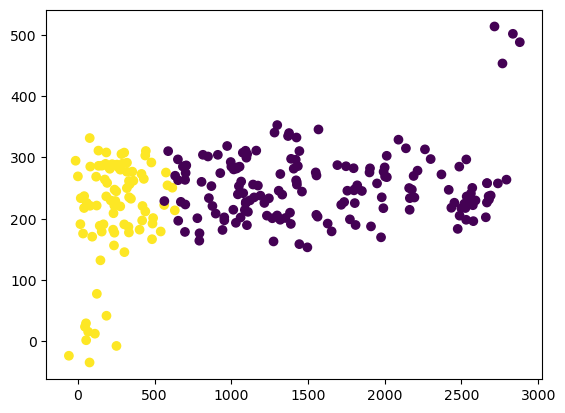

In [29]:
# visualise
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.show()